# LeetCode #168: Excel Sheet Column Title

https://leetcode.com/problems/excel-sheet-column-title/

## Comparison of Approaches
| Approach | Time | Space |
|---|---|---|
| Base-26 Conversion ★ | O(log₂₆ n) | O(log₂₆ n) |

## Understanding the Methods
### Brute Force
No simpler approach exists; this is fundamentally a base-26 encoding problem.

### Optimal: Base-26 Conversion ★
This is like base-26 but 1-indexed (A=1, Z=26, AA=27). At each step, subtract 1 from columnNumber to make it 0-indexed, take mod 26 to get the current letter, then divide by 26. Prepend the letters to get the final result.

## Solutions
### C#

In [ ]:
public class Solution {
    public string ConvertToTitle(int columnNumber) {
        var sb = new System.Text.StringBuilder();
        while (columnNumber > 0) {
            columnNumber--;
            sb.Insert(0, (char)('A' + columnNumber % 26));
            columnNumber /= 26;
        }
        return sb.ToString();
    }
}

### Python

In [ ]:
class Solution:
    def convertToTitle(self, columnNumber: int) -> str:
        result = []
        while columnNumber > 0:
            columnNumber -= 1
            result.append(chr(ord('A') + columnNumber % 26))
            columnNumber //= 26
        return ''.join(reversed(result))

### Go

In [ ]:
package main

import "fmt"

func convertToTitle(columnNumber int) string {
    result := []byte{}
    for columnNumber > 0 {
        columnNumber--
        result = append([]byte{byte('A' + columnNumber%26)}, result...)
        columnNumber /= 26
    }
    return string(result)
}

func main() {
    fmt.Println(convertToTitle(1))   // A
    fmt.Println(convertToTitle(28))  // AB
    fmt.Println(convertToTitle(701)) // ZY
}

### Rust

In [ ]:
pub struct Solution;

impl Solution {
    pub fn convert_to_title(mut column_number: i32) -> String {
        let mut result = Vec::new();
        while column_number > 0 {
            column_number -= 1;
            result.push((b'A' + (column_number % 26) as u8) as char);
            column_number /= 26;
        }
        result.iter().rev().collect()
    }
}

## Example Scenarios

### 1. Common Case — Single Letter
**Input:** `columnNumber = 1`
Decrement to $0$: $0 \bmod 26 = 0 \to$ `A`, then $0 / 26 = 0$ stops. Result `"A"`.

### 2. Slightly Complex — Two Letters, No Carry Trick
**Input:** `columnNumber = 28`
$28-1=27$: $27 \bmod 26 = 1 \to$ `B`, carry $27/26 = 1$. Then $1-1=0 \to$ `A`. Reading bottom-up: `"AB"`.

### 3. Edge Case: Time Factor — Three Letters
**Input:** `columnNumber = 701`
$701 \to$ `Y` (remainder 24) with carry $26$; $26 \to$ `Z`. Only $O(\log_{26} n)$ steps: `"ZY"`.

### 4. Edge Case: Space Factor — The 26 Boundary
**Input:** `columnNumber = 26`
This is why we subtract 1 first: $26-1=25$, $25 \bmod 26 = 25 \to$ `Z`, then $25/26 = 0$. Without the decrement it would wrongly carry. Result `"Z"`.

### 5. Almost-Impossible but Plausible — INT_MAX
**Input:** `columnNumber = 2147483647`
Seven base-26 digits unwind to `"FXSHRXW"`, still only a handful of iterations.


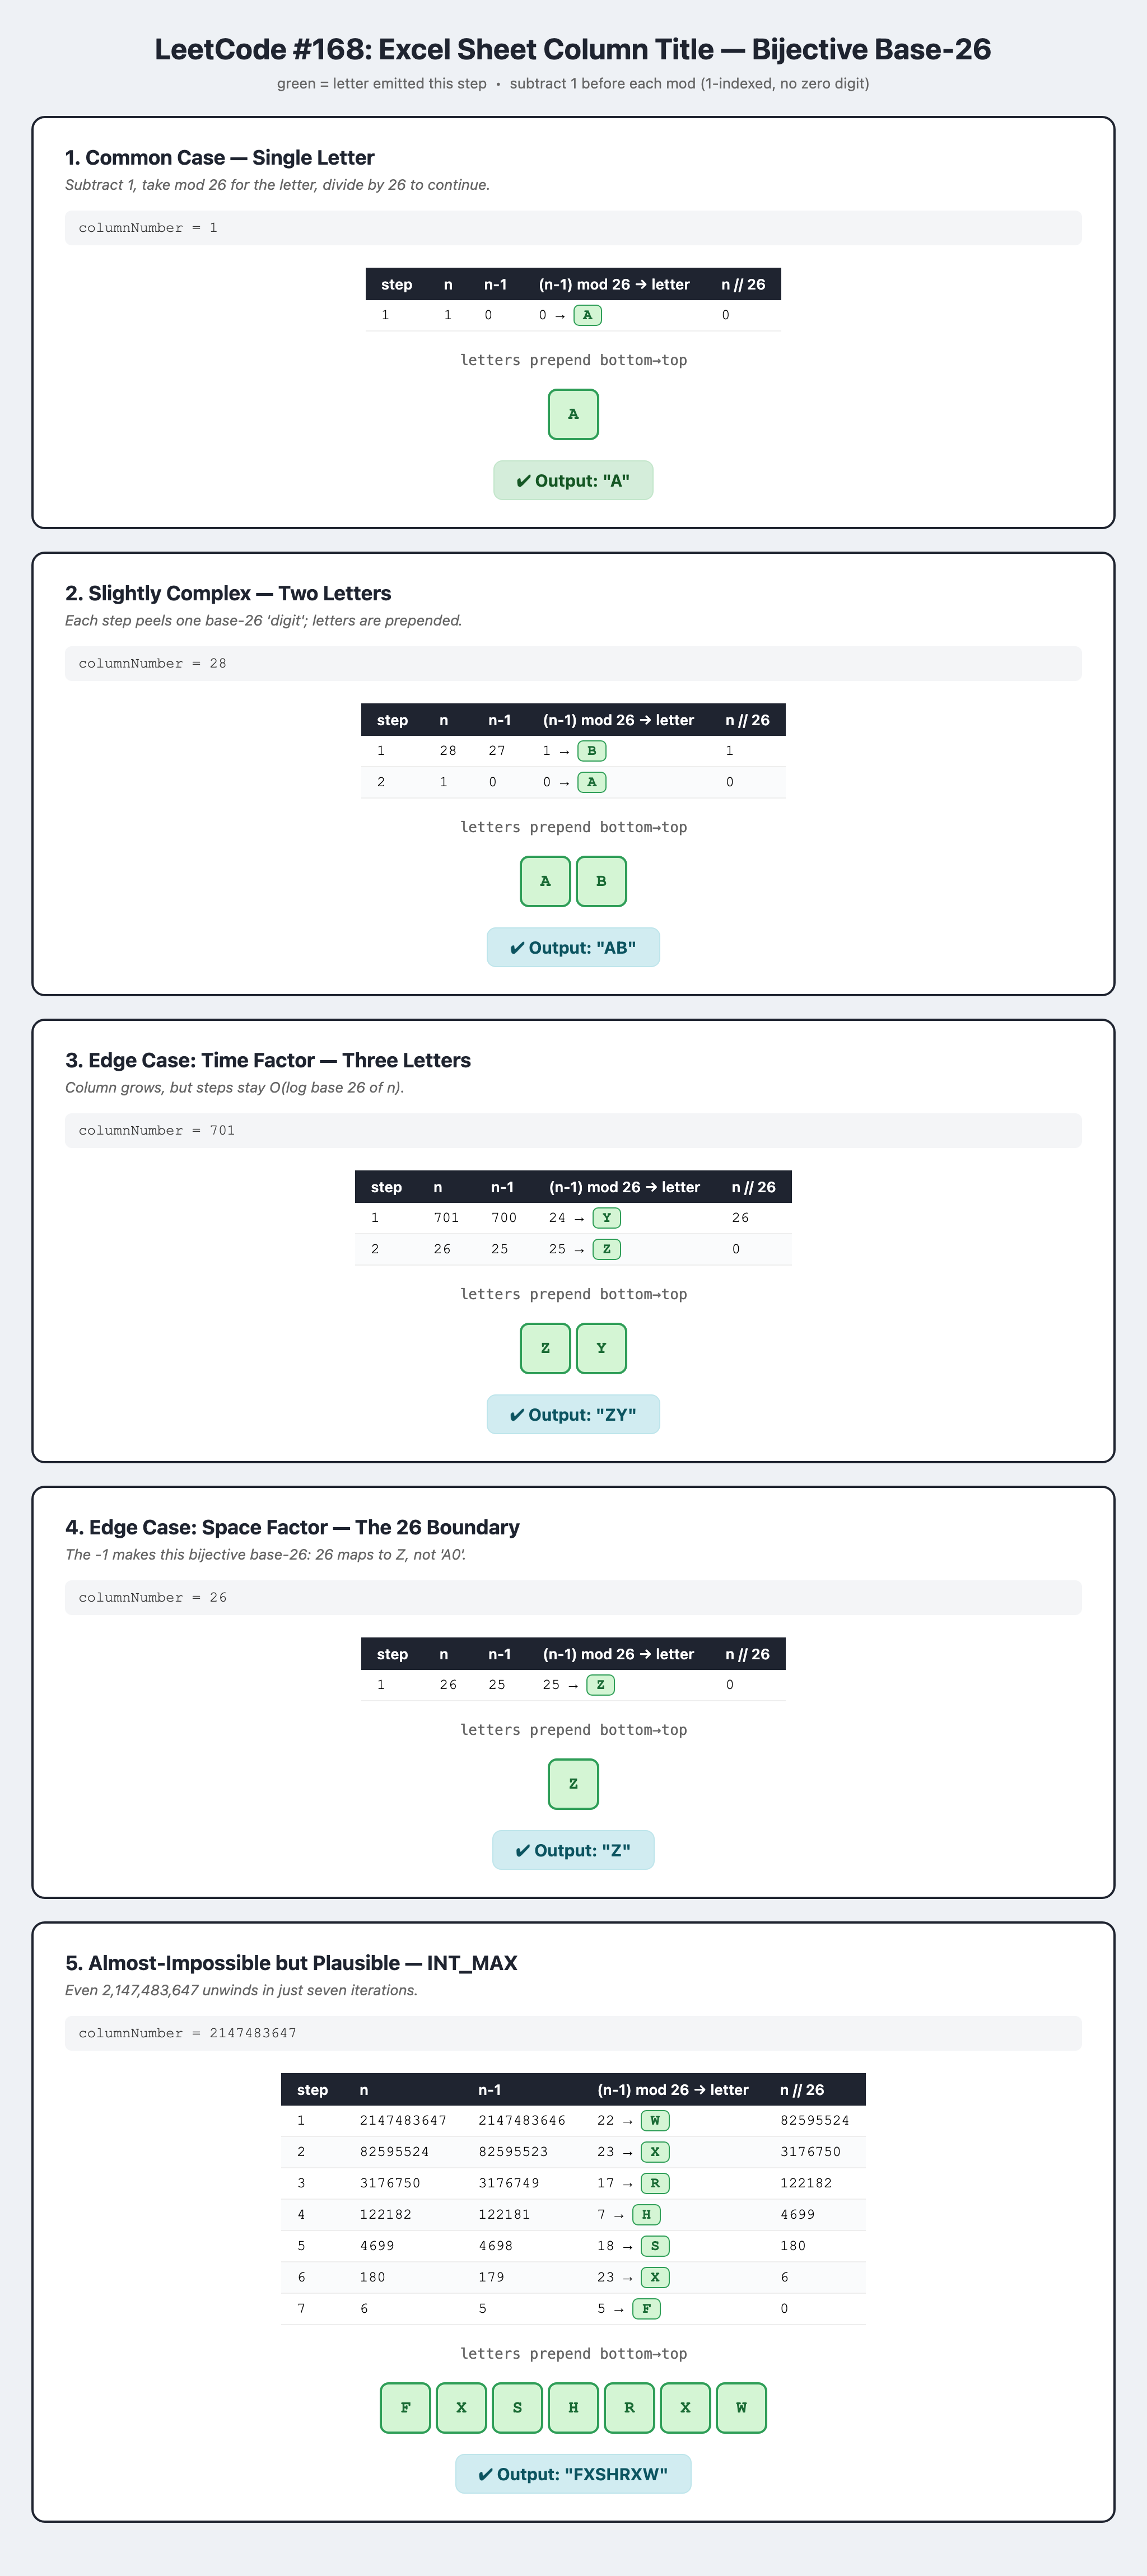